# CSAV workflow for TITAN2D

### TITAN2D is a geoflow simulation tool that, given initial parameters, will simulate granular flows over digital elevation models, or DEMs. For reference, the TITAN2D user guide is <span style="color:blue">[attached](https://raw.githubusercontent.com/TITAN2D/titan2d/master/doc/Titan2D_User_Guide.pdf).

### Importing Libraries [Run but don't change]

In [1]:
# Don't change, just run
import subprocess
import pandas as pd
import numpy as np
import sys
import matplotlib.pyplot as plt
import os
import rioxarray as rxr
import rasterio as rio
import h5py
import cartopy.crs as ccrs
import glob

In [2]:
# Don't change, just run
sys.path.insert(0, "/home/jovyan/shared/Libraries")
import victor

### File Managment  [Change these] </span>

Notes from VICTOR team: Keep in mind that for the **GIS_GRASS** type, multiple arguments to specify file mapset/map locations are neccesary, and the DEM location for the **GDAL** format. Additionally, the GDAL format requires a geotiff, rather than an ascii shapefile. We highly recommend the **GDAL** format.

There are a variety of interesting but largely unecessary files that are output at the end of the simulation. Toggle the option below to remove them.

If you would like to create a gif of all the timesteps, please enable the option below. Keep in mind, this may take many minutes, depending on the number of iterations.

In [3]:
#The output files show things like momentum and thickness through time. You can set cleanup = False if you want to see these files.
#If you want a gif of the flow, you can set create_gif = True, but this will be slow. For the CSAV exercise, let's set it to False.
cleanup = False

create_gif = False

### Vital general parameters. [Change these] 

In the cell below, choose the format of the DEM and specify its path. Then, provide a scale for the simulation to accommodate, as well as the gravity of the planet being simulated. Properties to constrain the simulation time and/or number of interations are another optional input. Choosing the frequency of outputs by either iteration number and/or simulator time is vital to having comprehensive time series analysis.

In [4]:
# You can choose GIS_GRASS or GDAL. 
# For the CSAV exercise choose 'GDAL'
gis_format='GDAL'

# Path to the DEM. 
# For the CSAV exercise, choose the DEM we reprojected. Always make sure the file is in UTM!
# You can right click on the DEM in your files and choose "copy file path", but make sure the file below starts with "/home/jovyan/"
# You will need to get a new UTM DEM for your project
dem="/home/jovyan/Titan2D/Licancabur_utm_small_dem.tif"

#Length scale for simulation (m). 
# For the CSAV exercise, we know Licancabur can produce PDCs up to 15 km, so change this to 20000 m.
length_scale=20000.0

#Gravity for simulation. Don't change unless your volcano is on another planet.
gravity=9.8

# Set maximum iterations of the simulation (max_iter) and the maximum simulation time (max_time). 
# For the CSAV exercise, let's use a max_iter of 100000 and simulate 10 minutes (600 sec) of time by entering '600' for 'max_time'
max_iter=100000
max_time=200

#Set frequency and format of outputs.
#choose from {'xdmf', 'tecplot', 'meshplot','grasssites'}
#We recommend xdmf for use with paraview

#For the CSAV exercise we will leave this as "xdmf"
vizoutput="xdmf"

#Set interval for model outputs, either number of iterations (diter) or number of simulation seconds (dtime), both are valid. 
#For the CSAV exercise, we want this to run relatively fast, so we will only make an output every 60 sec. Set 'dtime' = '60'
diter=None
dtime=20

### Numerical parameters  [Change these]

Here, input the numeric parameters, such as adaptive mesh refinement and level of differential equation solving. 

AMR allows for scaling graularity of the flow for maximum accuracy. Als, please specify the number of cells that the pile will occupy at time $t=0$.

In [5]:
# These numeric parameters relate to the size of the adaptive mesh (how many cells to start with). 
# For the CSAV exercise, we won't change these.

#Enable adaptive mesh refinements
AMR=True

#Number of elements across smallest pile axis in the beginning of the simulation
number_of_cells_across_axis=16
    
#Numerical PDE solver order,{'First','Second'} is set of choices
order='First'

geoflow_tiny = None

### Material Model  [Change these]

The final required method is the material model used. 

Depending on the selection, a variety of parameters are required. We choose a simple material interaction model with *Coulomb* by default, but other materials and their required values are clearly supplied in the manual linked above.

In [6]:
# Set the rheological model, choose from 'Coulomb', 'TwoPhases-Pitman-Le', 'Voellmy-Salm' or 'Pouliquen-Forterre'. 
# For the CSAV exercise, we will choose 'Coulomb'.
model='Coulomb'

#Set internal friction angle IF COULOMB OR PITMAN-LE. 
#For the CSAV exercise, we will choose '30'. The internal friction angle does not have a huge effect.
int_frict=30.0

# Set bed friction angle IF COULOMB OR PITMAN-LE. 

# CSAV notes: This is where we use a volume vs. ∆H/L regression to decide on a value. For the exercise we will model a ~10 M m3 (0.01 km3). 
# From the FlowDat database regression, we see that a good ∆H/L value for dome-collapse flows is about 12 degrees. Set the bed_frict to 12.0 
# For projects, you will need to decide on scenario volumes and choose ∆H/L values appropriate for those volumes.

bed_frict=16.0

# The following parameters are for other rheologies that we won't use for CSAV, so don't change them.

# Set mu/xi IF VOELLMY-SALM
mu = None

xi = None

# Set angles and material property IF POULIQUEN-FORTERRE
#CSAV: We won't change these.

phi1, phi2, phi3 = 30,30,30

beta = .65

l_material = 1e-3

### (Optional) Add Pile  [Change these]

Extra piles or additional areas of geoflow flux can optionally be added. 

We need at least one pile by default, but multiple can be added.

In [7]:
#Flag to set a pile of debris, will not be included unless set to True

# For the CSAV exercise we will use a pile source (like a dome-collapse PDC). So set 'addPile=True'
addPile = True

#Choose from {Paraboloid, Cylinder}.

#CSAV: A dome-collapse is like a Paraboloid. For a column-collapse, you could use a cylinder.
#For the CSAV exercise, use a Paraboloid
pile_type='Paraboloid'

#CSAV: We want the pile volume to match the volume we want to simulate. For this exercise, we are modeling a 10 M m3 PDC, so let's use the dome_volume_calculator spreadsheet in the CSAV file.
# The formula is 1/2 * pi * major_radius * minor_radius * height
# For the Licancabur exercise a dome with a major radius of 265 m, a minor radius of 215 m, and a height of 115 m results in a volume of about 10.3 M m3.
# You will need to change these values for the project!

#Height of pile in meters
#CSAV: Use 115 m for Licancabur. You will need to change this for the project.
height=80.0

#UTM x,y values of pile.
# CSAV: In QGIS, find where you want to center the pile at the summit of the volcano.
# CSAV: For Licancabur, use 614414.053, 7474371.278. You will need to change this for the project.
pile_center=[614414.053, 7474371.278]

#Major, minor radius in m of pile
#CSAV: use 265 for the major radius and 215 for the minor radius. You will need to change this for the project.
pile_radii=[150, 100]

# Degrees the pile is rotated (Optional)
# This is only needed for non-circular piles. For a volcano with a breached crater, or to model flows in one direction, you might want to add a direction that you know the flow will go. 
# East is 0, South is -90, West is -180, and North is 90.
# For the CSAV Licancabur exercise, use -135, so it points toward the SW. You will need to change this for the project.
orientation = -135

# Initial velocity of pile (Optional)
# For the CSAV Licancabur exercise, use 0. If you were modeling a lateral blast, you might want an initial velocity.
Vmagnitude = 0.0

# Initial direction of pile velocity (Optional)
# For the CSAV Licancabur exercise use 0. For a volcano with a breached crater, you might want to add a direction that you know the flow will go. 
# East is 0, South is -90, West is -180, and North is 90.
Vdirection = 0

# If using Pitman-Le, please enter volume fraction, otherwise leave as none
# For the CSAV exercise, don't change.
volume_fraction = None

### (Optional) Add flux  [Change these]

The flux here is an optional additional event.

We default to not adding it in this example workflow, but provide the ability to enable it with a simple flag. This will add a linearly decreasing source between two set times. 

In [8]:
#For the CSAV exercise, don't change anything here.
#Flag to add an additional source of flux
addFlux = False

influx=3.3

#Set start time in simulation seconds
start_time=10

#Set end time in simulation seconds
end_time=20

#UTM x,t values of flux 
flux_center=[633394.0, 2163411.0]

#Major, minor radius in m of flux
flux_radii=[33.0,33.0]

### (Optional) Discharge Plane  [Change these]

The discharge plane below is another optional addition.

By setting UTM coordinates for the beginning and endpoints, the model will calculate the amount in cubic meters that passes between those two points. It is disabled by default for simplicity's sake.

In [9]:
#For the CSAV exercise, don't change anything here.
#Set flag for discharge plane, oterwise will be ignored
addDischargePlane = False

#Below, set UTM bounds for the discharge plane
x_a=637380.0

y_a=2145800.0,

x_b=664380.0

y_b=2169800.0

### Run this cell to format the input [Run but don't change]

In [10]:
inp = f"""sim=TitanSimulation(overwrite_output=True)

sim.setGIS(
    gis_format='{gis_format}',
    gis_map='{dem}'
)

sim.setScale(
    length_scale={length_scale},
    gravity_scale={gravity},
)

sim.setNumProp(
    AMR={AMR},
    number_of_cells_across_axis={number_of_cells_across_axis},
    order='{order}',
"""
if geoflow_tiny:
    inp+=f"geoflow_tiny={geoflow_tiny},\n"
inp += f"""
)
sim.setMatModel(
    model='{model}',
    """
if model == "Coulomb" or model == "TwoPhases-Pitman-Le":
    inp+= f"""int_frict={int_frict},
    bed_frict={bed_frict}
)
"""
elif model == "Voellmy-Salm":
    inp+= f"""mu={mu},
    xi={xi}
)
"""
elif model == "Pouliquen-Forterre":
    inp+= f"""phi1={phi1},
        phi2={phi2},
        phi3={phi3},
        Beta={beta},
        L_material={l_material},
    )
    """
if addPile:
    inp+=f"""sim.addPile( 
    pile_type='{pile_type}',
    height={height},
    center={pile_center},
    radii={pile_radii},
    orientation={orientation},
    Vmagnitude={Vmagnitude},
    Vdirection={Vdirection},"""
    if volume_fraction:
        inp+=f"""    vol_fract={volume_fraction},"""
    inp+=f"""
)
"""
if addFlux:
    inp+=f"""sim.addFluxSource(
    pile_type='{pile_type}',
    influx={influx},
    start_time={start_time}
    end_time={end_time},
    center={flux_center},
    radii={flux_radii}
)
"""
if addDischargePlane:
    inp+=f"""sim.addDischargePlane(
    x_a={x_a},
    y_a={y_a},
    x_b={x_b}, 
    y_b={y_b}
)
"""
inp+= f"""sim.setTimeProps(
    max_iter={max_iter},"""
if max_time is not None:
    inp += f"""
    max_time={max_time}"""
inp += f"""
)

sim.setTimeSeriesOutput(
    vizoutput=('{vizoutput}'),
    diter={diter},
"""
if dtime is not None:
    inp += f"""
    dtime={dtime}"""
inp += f"""
)
#start simulation
sim.run()"""
with open("input.py",'w') as f:
    f.write(inp)

### Specify the number of threads you would like to use here. [Change this] 

We don't recommend any more than the number of CPUs you chose on startup.

In [11]:
# For the CSAV exercise, set to '4'
threads = 4

### Run Titan here! [Run but don't change]

Titan outputs updates at **every** timestep, so we suppress the output here for clarity.

In [12]:
# Don't change, just run
# Run Titan2D. This will take some time, don't proceed until the [*] changes to [number].
subprocess.run("export GDAL_DRIVER_PATH=''; ./titan -nt " + str(threads) + " input.py",shell=True, stderr=subprocess.DEVNULL)

Python home: /srv/conda/envs/notebook
Executable location: /home/jovyan/shared/Models/titan2d/bin/titan
python home: /srv/conda/envs/notebook
Titan2d 4.1.0
Executable location: /home/jovyan/shared/Models/titan2d/bin/titan
-------------------------------------------------------------------------------

Set threads number to 1


preproc...
The GIS region is:  x = 5.849262e+05 to 6.449225e+05   y = 7.444421e+06 to 7.505334e+06.
The simulation region is:  x = 5.849262e+05 to 6.449225e+05   y = 7.444421e+06 to 7.505334e+06.

GIS:
	gis_format: 2
	gis_main: 
	gis_sub: 
	gis_mapset: 
	gis_map: /home/jovyan/Titan2D/licancabur_new_utm.tiff
	gis_vector: 
	extramaps: 0
	region_limits_set 0
Piles:    (Number of piles: 1)
	Pile 0
		Maximum Initial Thickness, P (m):100.000000
		Center of Initial Volume, xc, yc (UTM E, UTM N): 614414.053000 7474371.278000
		Major and Minor Extent, majorR, minorR (m, m): 250.000000 200.000000
		Orientation (angle [degrees] from X axis to major axis): -135.000000
		Init

CompletedProcess(args="export GDAL_DRIVER_PATH=''; ./titan -nt 4 input.py", returncode=0)

### Select Output Time [Run this, only change where specified]

Here, please choose a point in the time series to display.

Every cell after the step input can be run without alteration.

In [13]:
# Don't change, just run
if max_iter == None or diter == None:
    print("From this simulation, we have", int(np.ceil(max_time/dtime)), "( 0 -", int(np.ceil(max_time/dtime)) ,") steps. Please input below what snapshot you would like to see.")
else:
    print("From this simulation, we have", int(np.ceil(max_iter/diter)), "( 0 -", int(np.ceil(max_iter/diter)) - 1 ,") steps. Please input below what snapshot you would like to see.")

From this simulation, we have 3 ( 0 - 3 ) steps. Please input below what snapshot you would like to see.


In [15]:
# The cell above says "From this simulation, we have y (x - y) steps. Below, choose a number to see plotted.
step = 3

### Plotting the Output [Run but don't change]

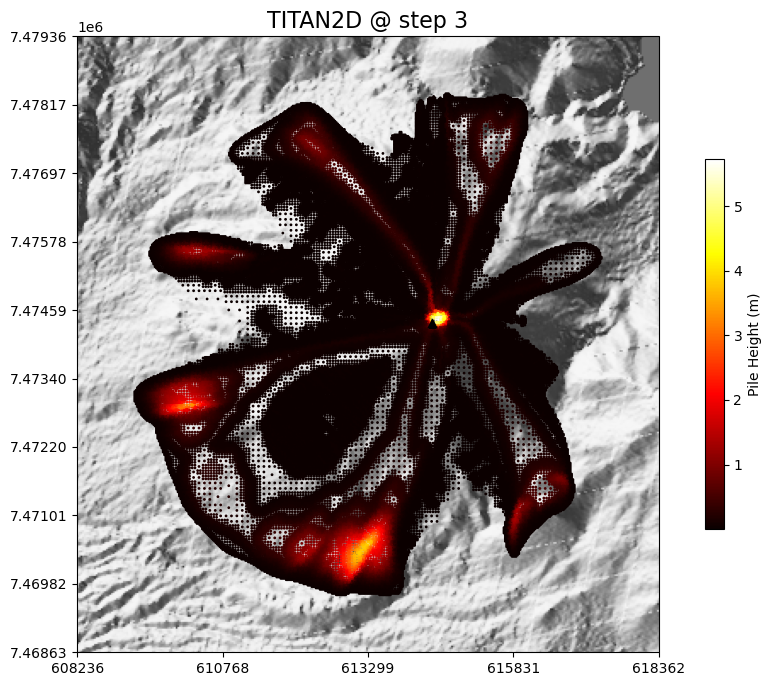

In [16]:
# Don't change, just run
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.epsg(32628))

victor.plot_titan(dem, step,fig, ax, pile_center)

In [18]:
# Don't change, just run
# This will make the ascii output file
!Rscript conv2.R

[1] "Beginning to create table, please wait..."
[1] "All done! File is in directory:" "/home/jovyan/Titan2D"           


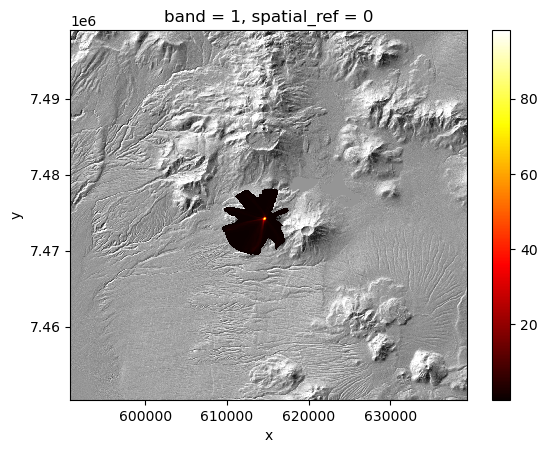

In [20]:
# Don't change, just run
import xrspatial as xrs
pile_colima = rxr.open_rasterio("pile_colima.asc",masked=True)
colima = rxr.open_rasterio(dem,masked=True)
c = colima.sel({"band": 1})
colima = xrs.hillshade(c, 45, 30)
pile_colima = pile_colima.where(pile_colima.values > .01)
colima.plot(cmap="Grays", add_colorbar=False)
pile_colima.plot(cmap="hot")


In [19]:
# Don't change, just run
# For CSAV exercise, nothing will happen because we selected FALSE
if create_gif:
    fig = plt.figure(figsize=(12, 8))
    ax = plt.axes(projection=ccrs.epsg(32628))
    victor.make_titan_gif(dem,fig, ax,pile_center,max_iter,diter,"victor.gif")
    subprocess.run("rm flow_*.png", shell=True)



In [21]:
# Don't change, just run
# For CSAV exercise, nothing will happen because we selected FALSE
if cleanup:
    subprocess.run("rm *.-00001", shell=True)